# Voltage rule, fair comparison: numerical vs analytical model, each with the main phase and with the peak-to-peak

So far each model was scored against a different recorded quantity: the numerical model (mine) against the **main phase** (each pair's
demeaned 25-sample trace at the sample of the largest |V|), the analytical model (Denis) against his **signed peak-to-peak** (PTP).
Here both models are run with both quantities, 4 combinations:

| | recorded = main phase | recorded = signed PTP |
|---|---|---|
| numerical (interior 4) | `cluster_assign/mine_N150_tank_barriers_int4/<video>.npz` `model_raw` vs `recorded` | `model_raw` vs Denis' `recorded_ptp` |
| analytical | Denis' `predicted_ptp` vs the main phase | `predicted_ptp` vs `recorded_ptp` |

For each combination, everything is refitted in the same way on the **same 4000 clean isolated EODs** (1000 per fish,
`clean_emitter_set_71/best1000_per_fish_71.csv`):
- **sign**: the constant sign that makes the model agree with the recording (Denis' signed PTP has the opposite sign to the main phase);
- **factors**: per EOD the emitter's ratios |recorded| / |model| on the 2 loudest recorded pairs (same sign, model |v| >= 5% of its
  max); fish factor a_f = median of the fish's ratios; signed-electrode factor e_k = median of ratio / a_f on electrode k (the pole of
  the pair nearer to the emitter's midline, each model's own electrode layout); missing electrode: 1.

Voltage rule: predicted = sign x a_f x e_k x model, the EOD goes to the fish with the smallest L2 in volts. Scored on the EODs with all
4 midlines (the same EODs and consecutive pairs for every combination): **median L2 of the assigned fish in volts**, the same divided by
max |recorded|, and refractory violations (< 6.5 ms, same fish, % of valid consecutive pairs). The predicted electric fields are the
saved ones: nothing is recomputed except the factors and the assignment.

In [1]:
import os
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline

BASE = 'results/eod_assign_4fish_kaden'
OUT = f'{BASE}/refractory_violations/conductivities_vs_denis/recorded_quantity'; os.makedirs(OUT, exist_ok=True)
FISH, LIM_MS = 'ABCD', 6.5
MODELS, QUANT = ['numerical', 'analytical'], ['main phase', 'peak-to-peak']
COMBOS = [(m, q) for q in QUANT for m in MODELS]
COL = {'numerical': '#4292c6', 'analytical': '#e6550d'}; HATCH = {'main phase': None, 'peak-to-peak': '//'}; LS = {'main phase': '-', 'peak-to-peak': '--'}
plt.rcParams.update({'axes.spines.top': False, 'axes.spines.right': False, 'axes.grid': True, 'grid.color': '#e6e6e3', 'axes.axisbelow': True})
VIDEOS = sorted(v[:-4] for v in os.listdir(f'{BASE}/cluster_assign/mine_N150_tank_barriers_int4') if v.endswith('.npz'))
hours = lambda t: int(t[:2]) + int(t[3:5]) / 60 + int(t[6:8]) / 3600

def poles(path):
    EL = pd.read_csv(path).sort_values('pair')
    plus = np.array([(r.x1, r.y1) if str(r.pol1).strip() == '+' else (r.x2, r.y2) for _, r in EL.iterrows()], float)
    minus = np.array([(r.x2, r.y2) if str(r.pol1).strip() == '+' else (r.x1, r.y1) for _, r in EL.iterrows()], float)
    return plus, minus
POLES_ANA = poles('data/electrodes/electrodes_signed_px_coord_4-fish.csv')    # numerical: its saved nearer_pole (its own layout)

def nearer_pole(mids, plus, minus, chunk=1500):
    out = np.zeros(mids.shape[:2] + (10,), np.int8)
    for s in range(0, len(mids), chunk):
        xy = mids[s:s + chunk, :, :, ::-1] * 911
        dp = np.linalg.norm(xy[:, :, :, None] - plus[None, None, None], axis=-1).min(2)
        dm = np.linalg.norm(xy[:, :, :, None] - minus[None, None, None], axis=-1).min(2)
        out[s:s + chunk] = (dm < dp)
    return out

def load(t, rows=None):
    '''recorded (main phase, PTP), model (numerical, analytical; raw sign), nearer pole per model, all for the EOD rows `rows` (default all)'''
    z = np.load(f'{BASE}/cluster_assign/mine_N150_tank_barriers_int4/{t}.npz'); dz = np.load(f'{BASE}/{t}/denis_predicted_voltages.npz', allow_pickle=True)
    rows = np.arange(len(z['frames'])) if rows is None else np.asarray(rows)
    mz = np.load(f'{BASE}/{t}/midlines_by_frame.npz'); gi = {int(k): i for i, k in enumerate(mz['frames'])}
    fr = z['frames'][rows]; idx = np.array([gi.get(int(k), -1) for k in fr])
    mids = np.where(idx[:, None, None, None] >= 0, mz['mids'][np.clip(idx, 0, None)], np.nan)
    rec = {'main phase': z['recorded'][rows], 'peak-to-peak': dz['recorded_ptp'][rows]}
    mod = {'numerical': z['model_raw'][rows], 'analytical': dz['predicted_ptp'][rows]}
    pole = {'numerical': z['nearer_pole'][rows], 'analytical': nearer_pole(mids, *POLES_ANA)}
    return rec, mod, pole
print(len(VIDEOS), 'recordings')

71 recordings


## 1. Sign and factors per combination, fitted on the same 4000 clean EODs

In [2]:
S = pd.read_csv(f'{BASE}/clean_emitter_set_71/best1000_per_fish_71.csv')
CL = {c: dict(rec=[], mod=[], pole=[], fish=[]) for c in COMBOS}
for t, g in S.groupby('video'):
    rec, mod, pole = load(t, g.row.to_numpy()); j = g.fish.map(FISH.index).to_numpy(); ii = np.arange(len(g))
    for m, q in COMBOS:
        CL[(m, q)]['rec'].append(rec[q]); CL[(m, q)]['mod'].append(mod[m][ii, j]); CL[(m, q)]['pole'].append(pole[m][ii, j]); CL[(m, q)]['fish'].append(j)
FAC, rows = {}, []
for c in COMBOS:
    rec, mod, pole, fish = (np.concatenate(CL[c][k]) for k in ('rec', 'mod', 'pole', 'fish'))
    ok = np.isfinite(rec).all(1) & np.isfinite(mod).all(1)
    sign = np.sign(np.median(np.einsum('np,np->n', rec[ok], mod[ok])))
    R = []
    for i in np.flatnonzero(ok):
        pr = sign * mod[i]
        for p in np.argsort(-np.abs(rec[i]))[:2]:
            if np.sign(rec[i, p]) == np.sign(pr[p]) and abs(pr[p]) >= 0.05 * np.abs(pr).max():
                R.append((fish[i], p, pole[i, p], abs(rec[i, p]) / abs(pr[p])))
    R = np.array(R); f_, p_, s_, g_ = R[:, 0].astype(int), R[:, 1].astype(int), R[:, 2].astype(int), R[:, 3]
    a = np.array([np.median(g_[f_ == f]) for f in range(4)]); E = np.ones((10, 2))
    for p in range(10):
        for s in range(2):
            k = (p_ == p) & (s_ == s)
            if k.any(): E[p, s] = np.median(g_[k] / a[f_[k]])
    res = np.log(g_ / (a[f_] * E[p_, s_]))
    FAC[c] = dict(sign=sign, a=a, E=E)
    rows.append(dict(model=c[0], recorded=c[1], sign=int(sign), EODs=int(ok.sum()), ratios=len(R), ratios_per_EOD=len(R) / ok.sum(),
                     **{f'fish {f}': a[i] for i, f in enumerate(FISH)}, electrode_min=E.min(), electrode_max=E.max(),
                     explained_var_log_ratio=1 - res.var() / np.log(g_).var(), residual_spread_x=np.exp(np.subtract(*np.percentile(res, [75, 25])))))
FT = pd.DataFrame(rows); FT.to_csv(f'{OUT}/factors_per_combination.csv', index=False)
pd.DataFrame({f'{m} | {q}': np.r_[FAC[(m, q)]['a'], FAC[(m, q)]['E'].ravel()] for m, q in COMBOS},
             index=[f'fish {f}' for f in FISH] + [f'electrode {p}{s}' for p in range(1, 11) for s in '+−']).to_csv(f'{OUT}/factors_values.csv')
FT.round(4)

,model,recorded,sign,EODs,ratios,ratios_per_EOD,fish A,fish B,fish C,fish D,electrode_min,electrode_max,explained_var_log_ratio,residual_spread_x
0,numerical,main phase,-1,4000,7997,1.9992,0.3479,0.2787,0.4052,0.2699,0.5123,1.5239,0.7698,1.2370
1,analytical,main phase,-1,4000,8000,2.0000,0.0039,0.0030,0.0041,0.0028,0.6434,1.2941,0.6911,1.2407
2,numerical,peak-to-peak,1,4000,7997,1.9992,0.5750,0.4426,0.6372,0.4208,0.5080,1.5189,0.7789,1.2324
3,analytical,peak-to-peak,1,4000,8000,2.0000,0.0065,0.0048,0.0064,0.0043,0.6382,1.3024,0.7135,1.2360


## 2. Voltage rule on all 71 recordings, the 4 combinations

In [3]:
def violations(dt_ms, k):
    valid = (k[1:] >= 0) & (k[:-1] >= 0); v = valid & (k[1:] == k[:-1]) & (dt_ms < LIM_MS)
    return 100 * v.sum() / max(valid.sum(), 1)

rows = []
for t in VIDEOS:
    rec, mod, pole = load(t)
    d = pd.read_csv(f'{BASE}/{t}/denis_assignments.csv', usecols=['Time', 'all fish have a midline'], keep_default_na=False)
    dset = d['all fish have a midline'].astype(str).str.lower().eq('true').to_numpy(); dt = np.diff(d.Time.to_numpy()) * 1000
    assert len(d) == len(rec['main phase']), t
    for m, q in COMBOS:
        F = FAC[(m, q)]; R = rec[q]
        pred = F['sign'] * F['a'][None, :, None] * F['E'][np.arange(10)[None, None, :], pole[m]] * mod[m]
        dv = np.linalg.norm(R[:, None] - pred, axis=2)
        k = np.where(np.isfinite(dv).any(1), np.nanargmin(np.where(np.isfinite(dv), dv, np.inf), 1), -1)
        l2 = np.where(k >= 0, dv[np.arange(len(k)), np.clip(k, 0, None)], np.nan); rmax = np.abs(R).max(1)
        ok = dset & np.isfinite(l2)
        rows.append(dict(recording=t, hour=hours(t), model=m, recorded=q, n=int(ok.sum()), l2_V=np.median(l2[ok]),
                         l2_rel=np.median(l2[ok] / rmax[ok]), max_recorded_V=np.median(rmax[ok]),
                         l2_V_mean=l2[ok].mean(), l2_rel_mean=(l2[ok] / rmax[ok]).mean(), max_recorded_V_mean=rmax[ok].mean(), violations_pct=violations(dt, np.where(dset, k, -1))))
    del rec, mod, pole
P = pd.DataFrame(rows); P.to_csv(f'{OUT}/per_recording.csv', index=False)
SUM = P.groupby(['model', 'recorded'])[['l2_V', 'l2_rel', 'max_recorded_V', 'l2_V_mean', 'l2_rel_mean', 'violations_pct']].median().reindex(pd.MultiIndex.from_tuples(COMBOS))
SUM.to_csv(f'{OUT}/summary_medians.csv'); SUM.round(4)

,,l2_V,l2_rel,max_recorded_V,violations_pct
numerical,main phase,0.0224,0.3936,0.0602,0.2332
analytical,main phase,0.0258,0.4499,0.0602,0.3231
numerical,peak-to-peak,0.0360,0.3984,0.0966,0.2280
analytical,peak-to-peak,0.0414,0.4546,0.0966,0.3226


## 3. Median L2 (volts) and refractory violations

Lines: per recording (solid: main phase, dashed: peak-to-peak); bars: median over the 71 recordings, whiskers 25-75th percentile.
Within a recorded quantity the L2 in volts is directly comparable between the two models (same recorded numbers); between quantities
it is not (the PTP is ~1.6x the main phase), so the L2 / max |recorded| bars are added.

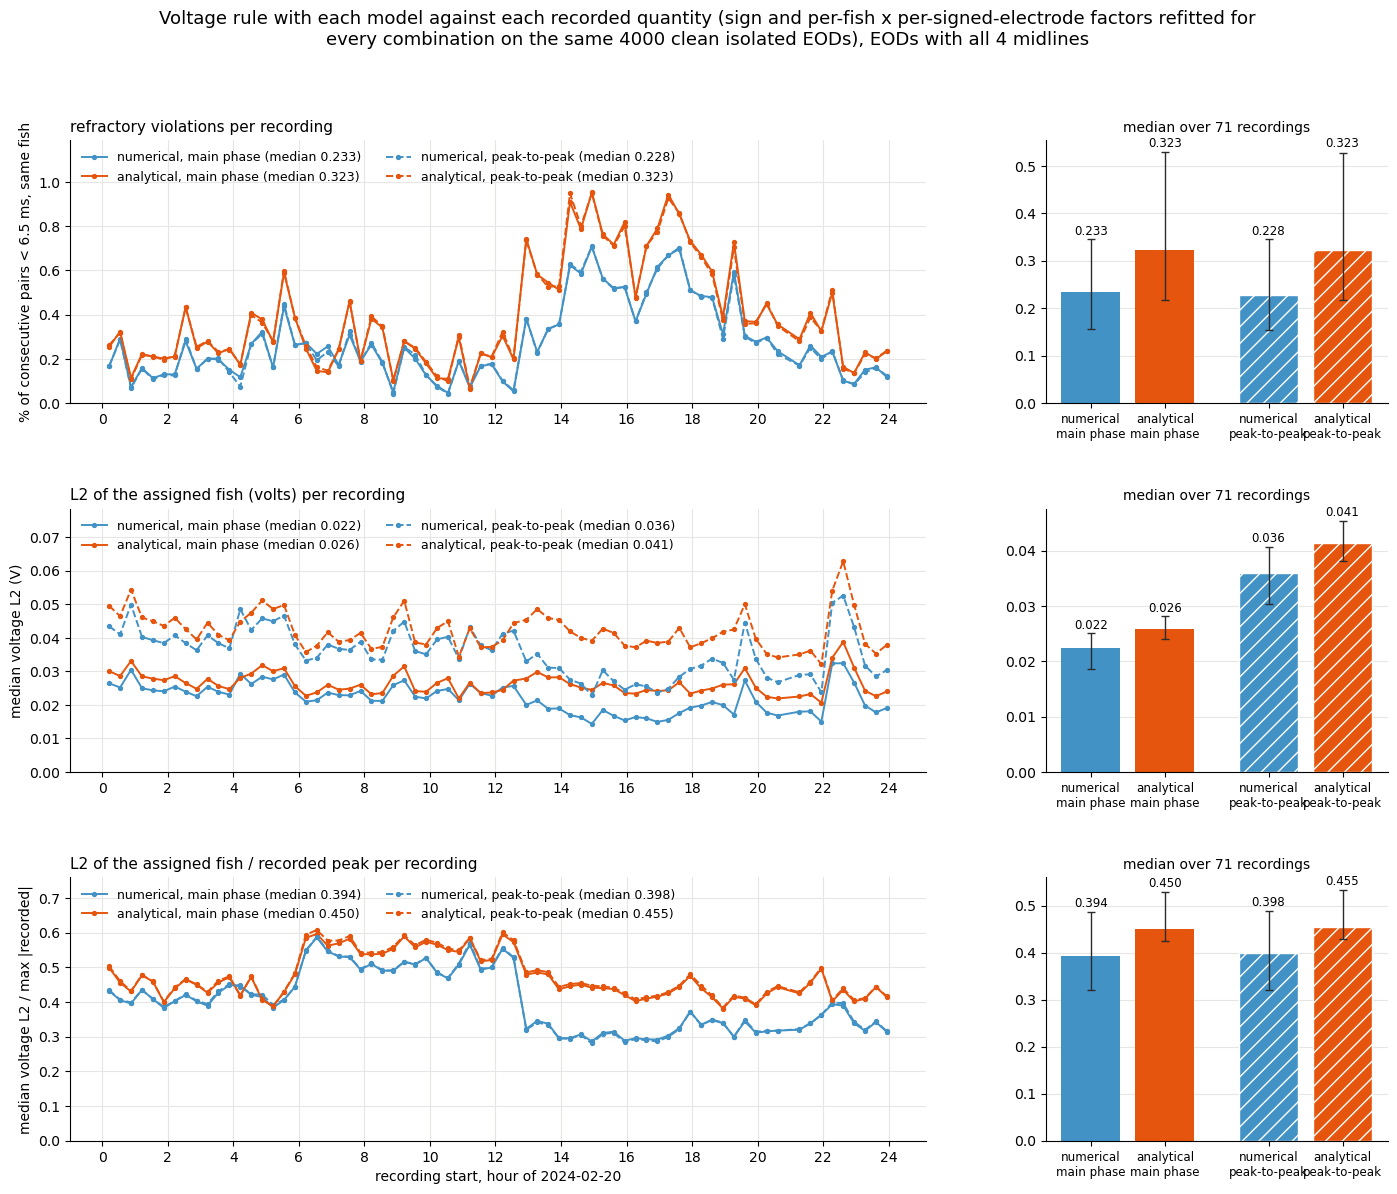

In [4]:
MEAS = [('violations_pct', f'% of consecutive pairs < {LIM_MS:g} ms, same fish', 'refractory violations'),
        ('l2_V', 'median voltage L2 (V)', 'L2 of the assigned fish (volts)'),
        ('l2_rel', 'median voltage L2 / max |recorded|', 'L2 of the assigned fish / recorded peak')]
fig, axs = plt.subplots(3, 2, figsize=(17, 13), gridspec_kw=dict(width_ratios=[3, 1.2], hspace=0.4, wspace=0.2))
for r_, (col, yl, ttl) in enumerate(MEAS):
    ax = axs[r_, 0]
    for m, q in COMBOS:
        g = P[(P.model == m) & (P.recorded == q)].sort_values('hour')
        ax.plot(g.hour, g[col], LS[q], marker='o', ms=2.8, lw=1.4, color=COL[m], label=f'{m}, {q} (median {g[col].median():.3f})')
    ax.set_ylabel(yl); ax.set_ylim(0, P[col].max() * 1.25); ax.set_xticks(range(0, 25, 2)); ax.set_title(ttl + ' per recording', loc='left', fontsize=11)
    ax.legend(frameon=False, fontsize=9, ncol=2, loc='upper left')
    ax = axs[r_, 1]
    for j, (m, q) in enumerate(COMBOS):
        y = P[(P.model == m) & (P.recorded == q)][col].to_numpy(); med = np.median(y); qq = np.quantile(y, [0.25, 0.75]); x = j + (j >= 2) * 0.4
        ax.bar(x, med, 0.8, color=COL[m], hatch=HATCH[q], edgecolor='white' if HATCH[q] else None)
        ax.errorbar(x, med, yerr=[[med - qq[0]], [qq[1] - med]], color='#2b2b2b', capsize=3, lw=1)
        ax.text(x, qq[1] * 1.01, f'{med:.3f}', ha='center', va='bottom', fontsize=8.5)
    ax.set_xticks([0, 1, 2.4, 3.4]); ax.set_xticklabels([f'{m}\n{q}' for m, q in COMBOS], fontsize=8.5); ax.grid(axis='x', visible=False)
    ax.set_title('median over 71 recordings', fontsize=10)
axs[-1, 0].set_xlabel('recording start, hour of 2024-02-20')
fig.suptitle('Voltage rule with each model against each recorded quantity (sign and per-fish x per-signed-electrode factors refitted for\n'
             'every combination on the same 4000 clean isolated EODs), EODs with all 4 midlines', y=0.98, fontsize=13)
fig.savefig(f'{OUT}/recorded_quantity_comparison.png', dpi=110, bbox_inches='tight'); plt.show()

## 4. The same with the **mean** L2 per recording

Lines: the mean L2 of the assigned fish over each recording's EODs; bars: median over the 71 recordings of those means. The mean is
pulled up by the few EODs with a very large L2 (badly predicted EODs), so it is larger than the median.

In [ ]:
MEAS = [('violations_pct', f'% of consecutive pairs < {LIM_MS:g} ms, same fish', 'refractory violations'),
        ('l2_V_mean', 'mean voltage L2 (V)', 'mean L2 of the assigned fish (volts)'),
        ('l2_rel_mean', 'mean voltage L2 / max |recorded|', 'mean L2 of the assigned fish / recorded peak')]
fig, axs = plt.subplots(3, 2, figsize=(17, 13), gridspec_kw=dict(width_ratios=[3, 1.2], hspace=0.4, wspace=0.2))
for r_, (col, yl, ttl) in enumerate(MEAS):
    ax = axs[r_, 0]
    for m, q in COMBOS:
        g = P[(P.model == m) & (P.recorded == q)].sort_values('hour')
        ax.plot(g.hour, g[col], LS[q], marker='o', ms=2.8, lw=1.4, color=COL[m], label=f'{m}, {q} (median {g[col].median():.3f})')
    ax.set_ylabel(yl); ax.set_ylim(0, P[col].max() * 1.25); ax.set_xticks(range(0, 25, 2)); ax.set_title(ttl + ' per recording', loc='left', fontsize=11)
    ax.legend(frameon=False, fontsize=9, ncol=2, loc='upper left')
    ax = axs[r_, 1]
    for j, (m, q) in enumerate(COMBOS):
        y = P[(P.model == m) & (P.recorded == q)][col].to_numpy(); med = np.median(y); qq = np.quantile(y, [0.25, 0.75]); x = j + (j >= 2) * 0.4
        ax.bar(x, med, 0.8, color=COL[m], hatch=HATCH[q], edgecolor='white' if HATCH[q] else None)
        ax.errorbar(x, med, yerr=[[med - qq[0]], [qq[1] - med]], color='#2b2b2b', capsize=3, lw=1)
        ax.text(x, qq[1] * 1.01, f'{med:.3f}', ha='center', va='bottom', fontsize=8.5)
    ax.set_xticks([0, 1, 2.4, 3.4]); ax.set_xticklabels([f'{m}\n{q}' for m, q in COMBOS], fontsize=8.5); ax.grid(axis='x', visible=False)
    ax.set_title('median over 71 recordings', fontsize=10)
axs[-1, 0].set_xlabel('recording start, hour of 2024-02-20')
fig.suptitle('Voltage rule with each model against each recorded quantity (sign and per-fish x per-signed-electrode factors refitted for\n'
             'every combination on the same 4000 clean isolated EODs), EODs with all 4 midlines; L2 = mean over the EODs of each recording',
             y=0.98, fontsize=13)
fig.savefig(f'{OUT}/recorded_quantity_comparison_mean.png', dpi=110, bbox_inches='tight'); plt.show()